# 第 09 章　换更大的模型 + 用你自己的照片

1. **SmolVLM-500M vs 256M**：两个模型哪里一样、哪里不同？大模型回答更好吗？"看图"的方式有变化吗？
2. **一键探索**：把第 02～06 章的全流程打包成一个函数，换任何照片都能直接看。

500M 的权重约 1 GB，已下载到 `models/SmolVLM-500M-Instruct/`。

In [1]:
import sys, pathlib  # 路径工具
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "vlmlab").exists())  # 找项目根目录
sys.path.insert(0, str(ROOT))  # 加入导入路径

import time  # 计时
import numpy as np  # 数组
import torch  # PyTorch
import torch.nn.functional as F  # 函数式接口
import matplotlib.pyplot as plt  # 绘图
from vlmlab import *  # 共享工具
from vlmlab.explore import explore  # 一键探索（源码见 vlmlab/explore.py）
from vlmlab.finetune import shapes_dataset, shape_accuracy  # 第 07 章的图形测试集

setup_matplotlib()  # 中文字体
seed_everything(0)  # 固定随机种子
device = get_device()  # mps
MODELS = {"256M": ROOT / "models" / "SmolVLM-256M-Instruct", "500M": ROOT / "models" / "SmolVLM-500M-Instruct"}  # 两个模型的目录
loaded = {name: load_smolvlm(device, model_dir=d) for name, d in MODELS.items()}  # 都加载上（float32 共约 3 GB）
photo = load_photo()  # 照片

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

## 1. 结构对比：大在哪里？

           视觉编码器       连接器      语言模型        合计
256M        86.4       7.1     163.0     256.5
500M        86.4      11.8     409.3     507.5
256M 语言模型：30 层，隐藏维度 576，9 个 Q 头 / 3 个 KV 头；连接器 (576, 12288)
500M 语言模型：32 层，隐藏维度 960，15 个 Q 头 / 5 个 KV 头；连接器 (960, 12288)


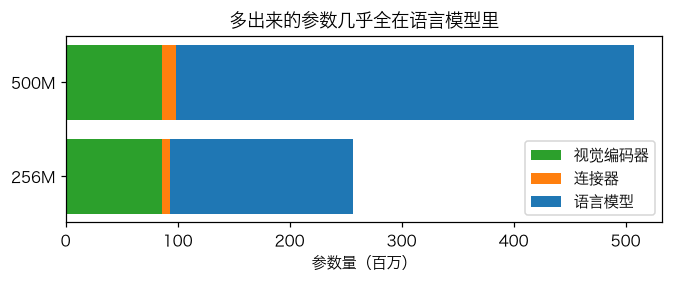

In [2]:
def part_sizes(model):  # 三大部件的参数量（百万）
    m = model.model  # 主体
    return {"视觉编码器": sum(p.numel() for p in m.vision_model.parameters()) / 1e6,  # SigLIP
            "连接器": sum(p.numel() for p in m.connector.parameters()) / 1e6,  # 线性层
            "语言模型": (sum(p.numel() for p in m.text_model.parameters()) + model.lm_head.weight.numel()) / 1e6}  # LLM + 输出层

sizes = {n: part_sizes(m) for n, (_, m) in loaded.items()}  # 统计
print(f"{'':6s}" + "".join(f"{k:>10s}" for k in sizes["256M"]) + f"{'合计':>10s}")  # 表头
for n, sz in sizes.items():  # 每个模型一行
    print(f"{n:6s}" + "".join(f"{v:>10.1f}" for v in sz.values()) + f"{sum(sz.values()):>10.1f}")  # 数值
for n, (_, m) in loaded.items():  # 语言模型超参数
    tc = m.config.text_config  # 文本配置
    print(f"{n} 语言模型：{tc.num_hidden_layers} 层，隐藏维度 {tc.hidden_size}，{tc.num_attention_heads} 个 Q 头 / {tc.num_key_value_heads} 个 KV 头；连接器 {tuple(m.model.connector.modality_projection.proj.weight.shape)}")  # 打印

fig, ax = plt.subplots(figsize=(7, 2.2))  # 堆叠条形图
left = np.zeros(2)  # 起点
for part, color in zip(sizes["256M"], ["tab:green", "tab:orange", "tab:blue"]):  # 三个部件
    vals = np.array([sizes[n][part] for n in sizes])  # 两个模型的该部件
    ax.barh(list(sizes), vals, left=left, color=color, label=part)  # 画
    left += vals  # 累加
ax.set_xlabel("参数量（百万）")  # 横轴
ax.legend(loc="lower right")  # 图例
ax.set_title("多出来的参数几乎全在语言模型里")  # 标题
plt.show()  # 显示

### 视觉编码器是同一个吗？
两个模型的 SigLIP 结构完全一样。权重呢？逐层比较两者的相对差异：0 表示完全相同。

patch embedding 相对差异 13.2%，位置编码 13.2%


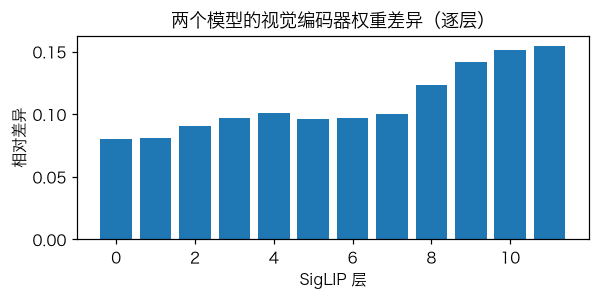

In [3]:
v256 = dict(loaded["256M"][1].model.vision_model.named_parameters())  # 256M 的视觉参数
v500 = dict(loaded["500M"][1].model.vision_model.named_parameters())  # 500M 的视觉参数
rel = {k: ((v256[k] - v500[k]).norm() / v256[k].norm()).item() for k in v256}  # 每个参数张量的相对差异
per_layer = [np.mean([v for k, v in rel.items() if f"layers.{i}." in k]) for i in range(12)]  # 每层平均
print(f"patch embedding 相对差异 {rel['embeddings.patch_embedding.weight']:.1%}，位置编码 {rel['embeddings.position_embedding.weight']:.1%}")  # 打印
plt.figure(figsize=(6, 2.4))  # 画布
plt.bar(range(12), per_layer)  # 每层
plt.xlabel("SigLIP 层")  # 横轴
plt.ylabel("相对差异")  # 纵轴
plt.title("两个模型的视觉编码器权重差异（逐层）")  # 标题
plt.show()  # 显示

**怎么理解**：两者都从同一个预训练 SigLIP 出发，再和各自的语言模型一起训练。差异不为 0，说明视觉编码器在训练 VLM 时也被调整过。

**观察**：差异从浅层的约 8% 逐层增加到最后一层的约 15%。浅层（边缘、颜色、纹理）是通用的，改得少；深层更贴近"要交给哪个语言模型"，改得多。这和 CNN 迁移学习里"浅层通用、深层专用"的经验一致。

## 2. 同样的问题，回答有什么不同？
使用切块模式（细节更多），同时记录生成时间。

In [4]:
questions = ["Describe this image.", "What is in the center of the bowl?", "What kind of meat is in the bowl?",  # 问题
             "What is the spoon made of?", "Is there any text in the image? What does it say?"]  # 续
for q in questions:  # 逐题
    print(f"Q: {q}")  # 问题
    for name, (proc, m) in loaded.items():  # 两个模型
        inp = build_inputs(proc, photo, q, split=True)  # 预处理
        t = time.time()  # 计时
        with torch.no_grad():  # 不要梯度
            out = m.generate(**inp, max_new_tokens=50, do_sample=False)  # 生成
        print(f"  [{name}, {time.time()-t:.1f}s] {proc.tokenizer.decode(out[0, inp['input_ids'].shape[1]:], skip_special_tokens=True).strip()}")  # 回答
    print()  # 空行

Q: Describe this image.


  [256M, 1.7s] An overhead shot shows a bowl of food, specifically an egg on top of a bed of seafood, with a small Shinto-style symbol in the corner. The food is in a bowl that is textured with an off-white or beige base,


  [500M, 2.0s] The image depicts a close-up view of a bowl of Japanese food, specifically a type of oden. The oden is a traditional Japanese dish that is typically served with a variety of ingredients, including meat, vegetables, and sauces. The bowl

Q: What is in the center of the bowl?


  [256M, 1.3s] There is food in the center of the bowl.


  [500M, 1.5s] There is a food item in the center of the bowl.

Q: What kind of meat is in the bowl?


...

  [500M, 1.4s] The bowl contains meat.

Q: What is the spoon made of?


  [256M, 1.2s] The spoon is made of metal.


  [500M, 1.4s] The spoon is made of metal.

Q: Is there any text in the image? What does it say?


  [256M, 1.2s] Yes, there is text visible in the image.


  [500M, 1.4s] Yes, there is text in the image.



**怎么看**：大模型的知识更多（本机运行时，它把这碗饭认成了日式料理 "oden"，小模型说是海鲜），但**"看得准"不一定更好**：两个模型都答不出肉是什么，两者用的是同一个规模的视觉编码器，图像也都只有 64～832 个 token。很多"看错"的问题出在视觉这一侧，单纯放大语言模型解决不了。

## 3. 第 07 章的图形任务：不微调能答对多少？

In [5]:
test_s = shapes_dataset(60, seed0=9000)  # 和第 07、08 章相同的测试集
for name, (proc, m) in loaded.items():  # 两个模型
    acc, ans = shape_accuracy(m, proc, test_s)  # 评估（两者都对才算对）
    s_ok = np.mean([s in a.lower() for a, (_, s, _) in zip(ans, test_s)])  # 只看形状
    c_ok = np.mean([c in a.lower() for a, (_, _, c) in zip(ans, test_s)])  # 只看颜色
    print(f"{name}：形状 {s_ok:.0%}，颜色 {c_ok:.0%}，两者都对 {acc:.0%}；回答例子：{ans[:3]}")  # 打印

256M：形状 48%，颜色 73%，两者都对 22%；回答例子：['The object is green.', 'The object is yellow.', 'The object is an orange square.']


500M：形状 100%，颜色 8%，两者都对 8%；回答例子：['The object is a square.', 'The object is a circle.', 'The object is a square.']


**观察**：大模型在这个任务上并不更好。本机运行时，500M 的形状全部答对，但几乎从不提颜色（"The object is a square."），而这个问题要求两个都说。没有经过微调时，回答格式更多取决于模型在训练数据里学到的习惯，而不是参数量。第 07 章只训练连接器 1 分钟，256M 就达到了 100%。

## 4. Logit Lens 对比：谁"看"得更准？
第 05 章的概念热力图：取最后一层在 64 个图像位置上的输出，看几个概念词的概率分布。

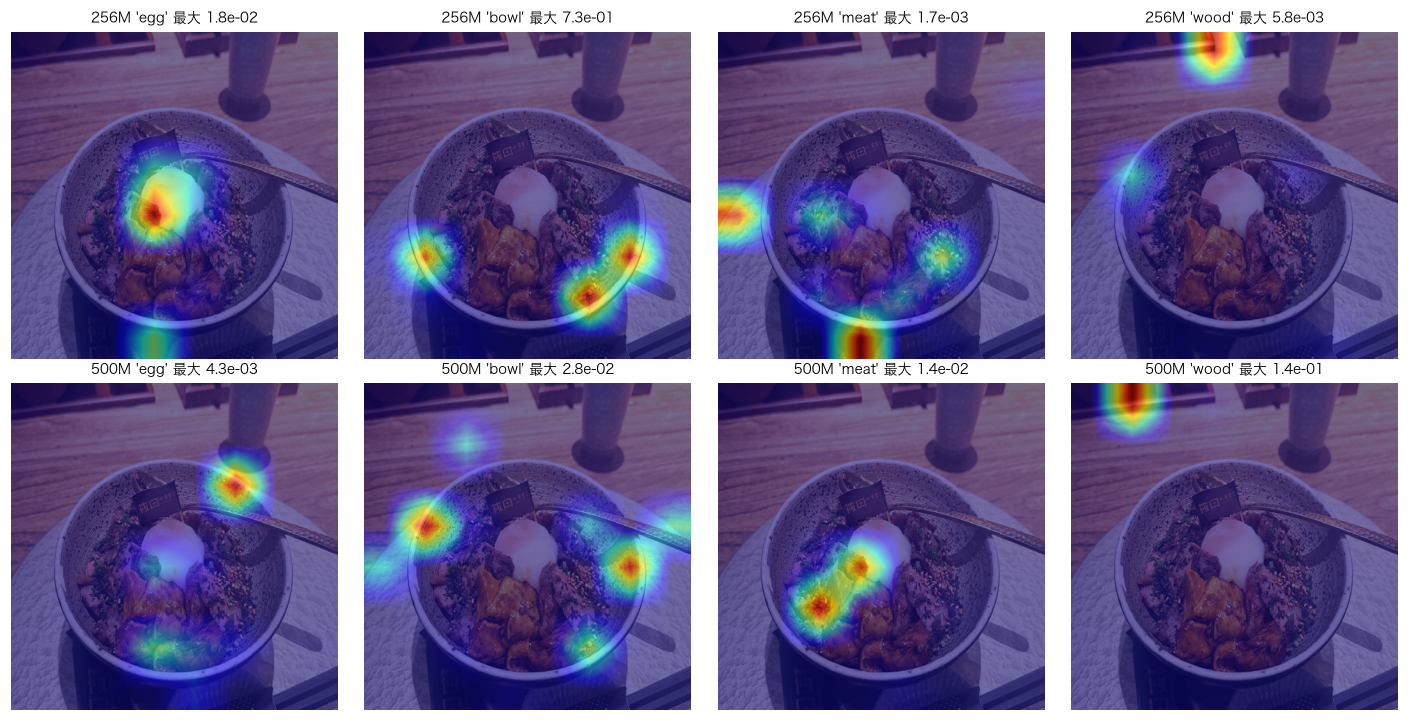

In [6]:
concepts = [" egg", " bowl", " meat", " wood"]  # 概念词
img512 = None  # 用于显示的图
fig, axes = plt.subplots(2, len(concepts), figsize=(13, 6.6))  # 两行：两个模型
for r, (name, (proc, m)) in enumerate(loaded.items()):  # 每个模型
    inp = build_inputs(proc, photo, "Describe this image.", split=False)  # 预处理
    img512 = (inp["pixel_values"][0, 0].cpu() * 0.5 + 0.5).clamp(0, 1)  # 显示用
    img_pos = (inp["input_ids"][0] == m.config.image_token_id).nonzero()[:, 0]  # 图像位置
    with torch.no_grad():  # 不要梯度
        p = m(**inp).logits[0, img_pos].softmax(-1)  # [64, vocab]
    for c, w in enumerate(concepts):  # 每个词
        heat = p[:, proc.tokenizer.encode(w, add_special_tokens=False)[0]].reshape(8, 8).cpu()  # 概率图
        overlay(img512, heat, ax=axes[r, c], title=f"{name} '{w.strip()}' 最大 {heat.max():.1e}")  # 叠加
plt.tight_layout()  # 调整
plt.show()  # 显示

**观察**：两个模型各有胜负。256M 的 `egg` 准确落在蛋上，`bowl` 落在碗边；500M 的 `meat` 落在肉块上、`wood` 落在木桌上，但它的 `egg` 偏到了碗外。模型大了，"在哪个格子写下哪个概念"并不会自动变准。

## 5. 一键探索：`explore()`
`vlmlab/explore.py` 把第 02～06 章串成一个函数，输出 6 个面板：
① 模型看到的输入 → ② SigLIP 三个层的 PCA → ③ 连接器输出 → ④ 最后一层 Logit Lens 词网格 → ⑤ 遮挡敏感度 → ⑥ 回答

先用 256M 和 500M 分别看这张照片：

===== 256M =====


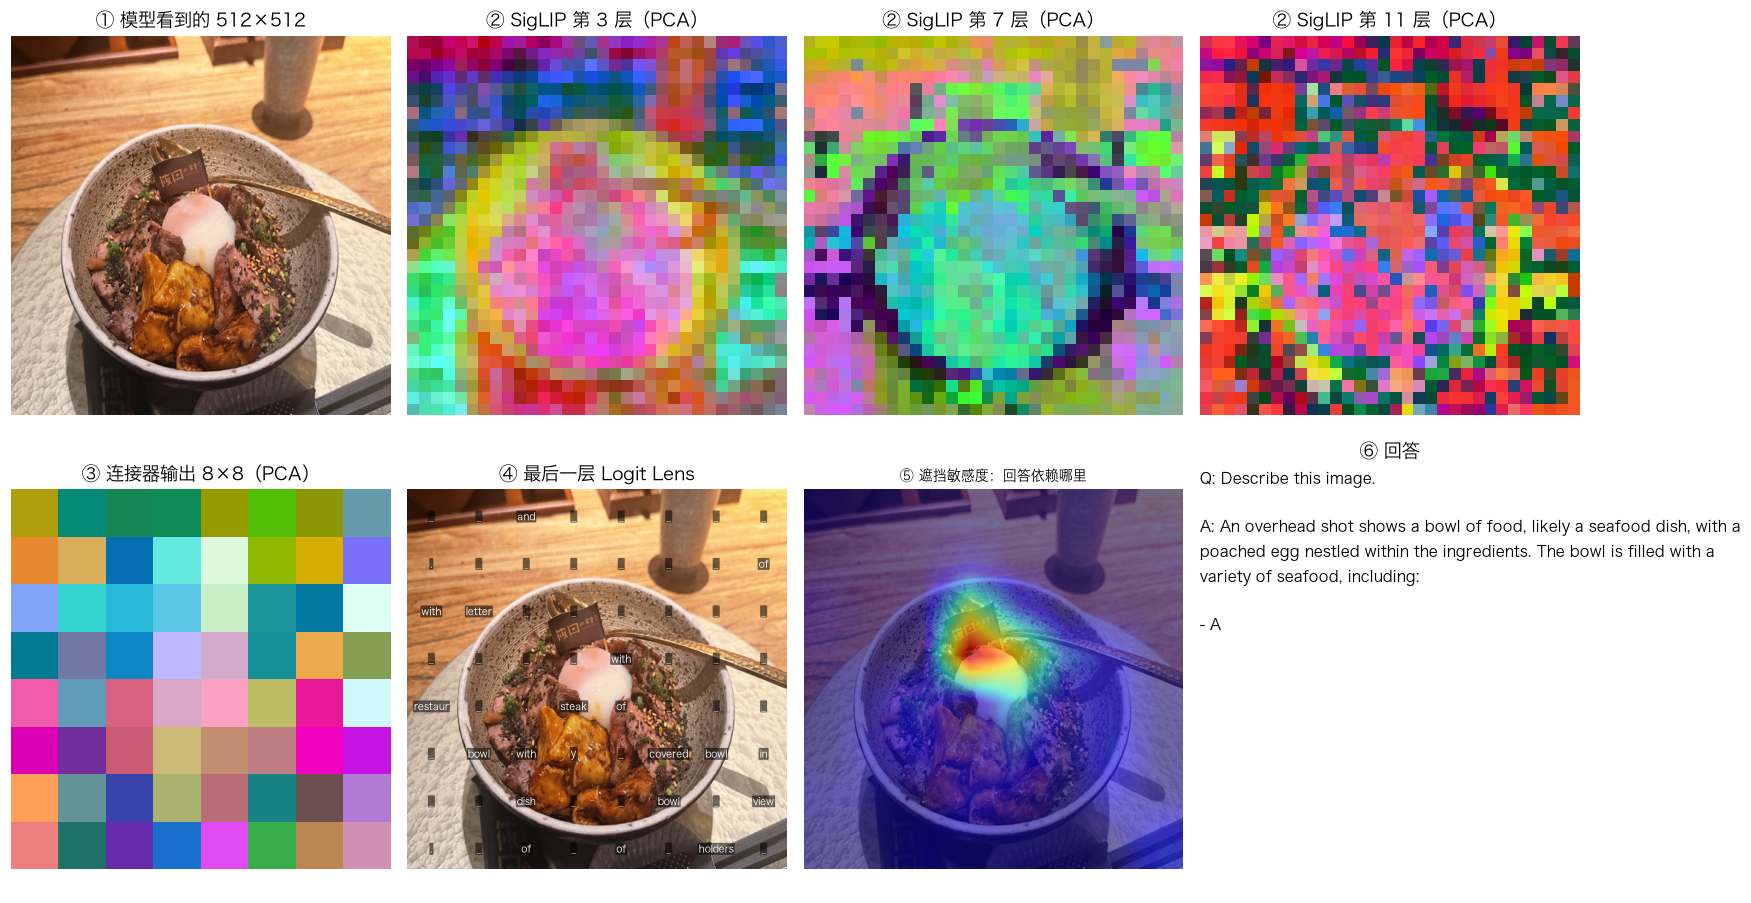

===== 500M =====


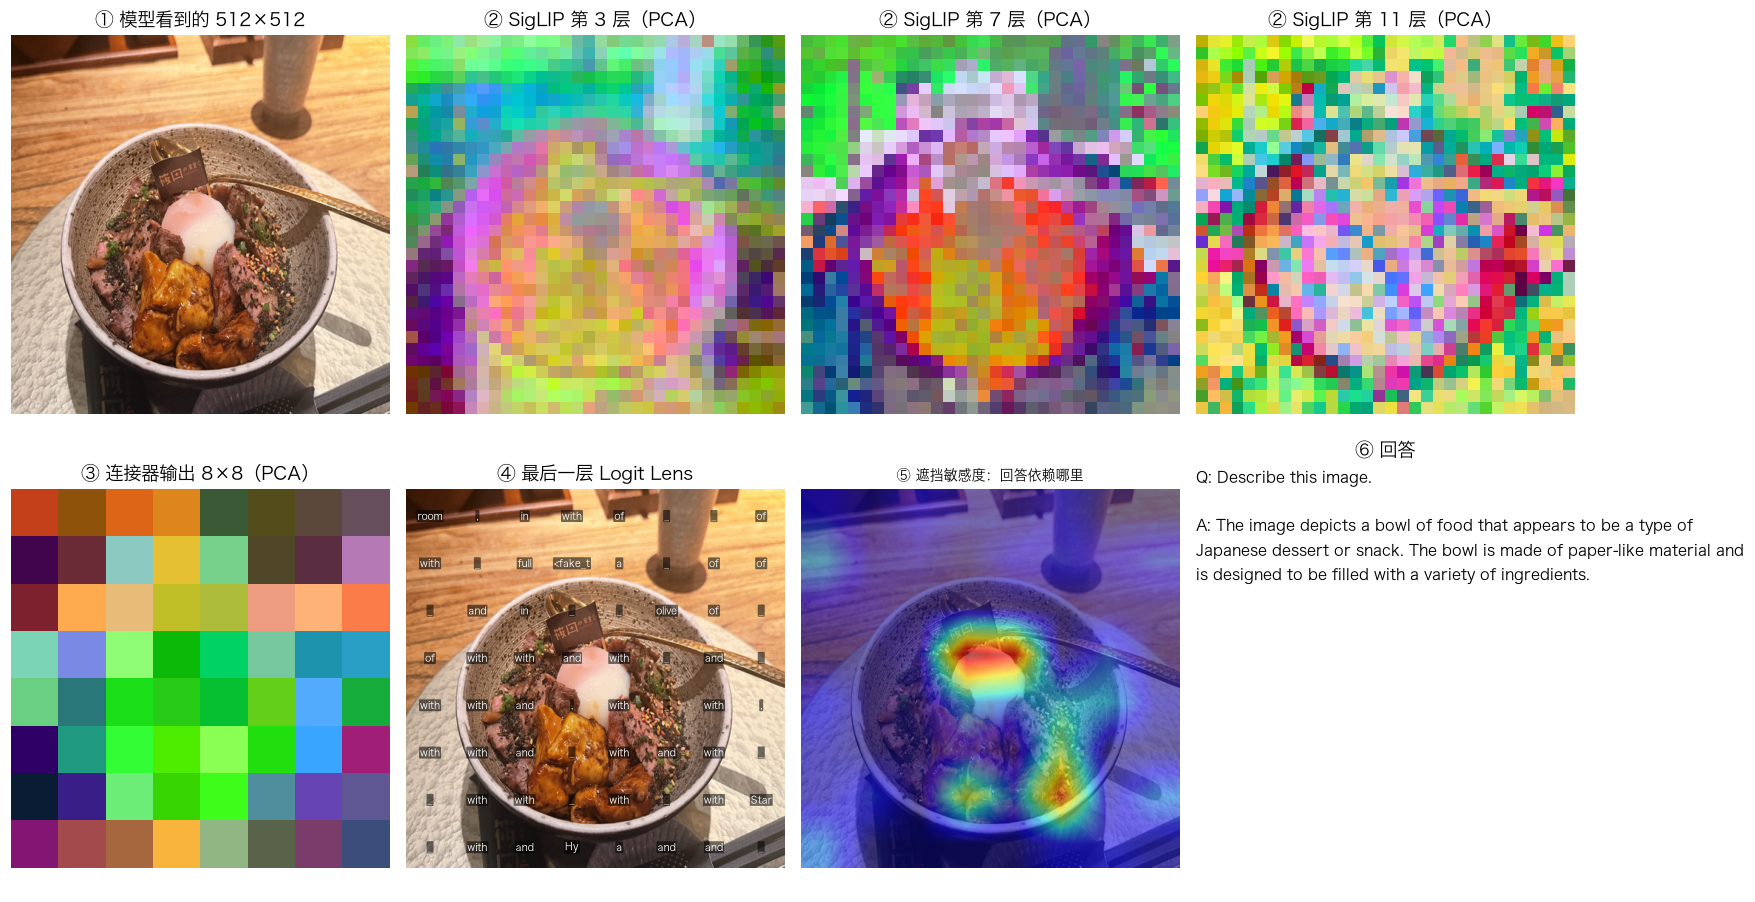

In [7]:
for name, (proc, m) in loaded.items():  # 两个模型
    print(f"===== {name} =====")  # 分隔
    res = explore(m, proc, photo, "Describe this image.")  # 一键探索

### 换成你自己的照片
把下面的 `MY_PHOTO` 改成你的照片路径（jpg/png 都行），问题也可以改，然后运行这一格。

没有指定照片时，用一张合成图演示：白底上一个红色圆形和一个蓝色正方形。

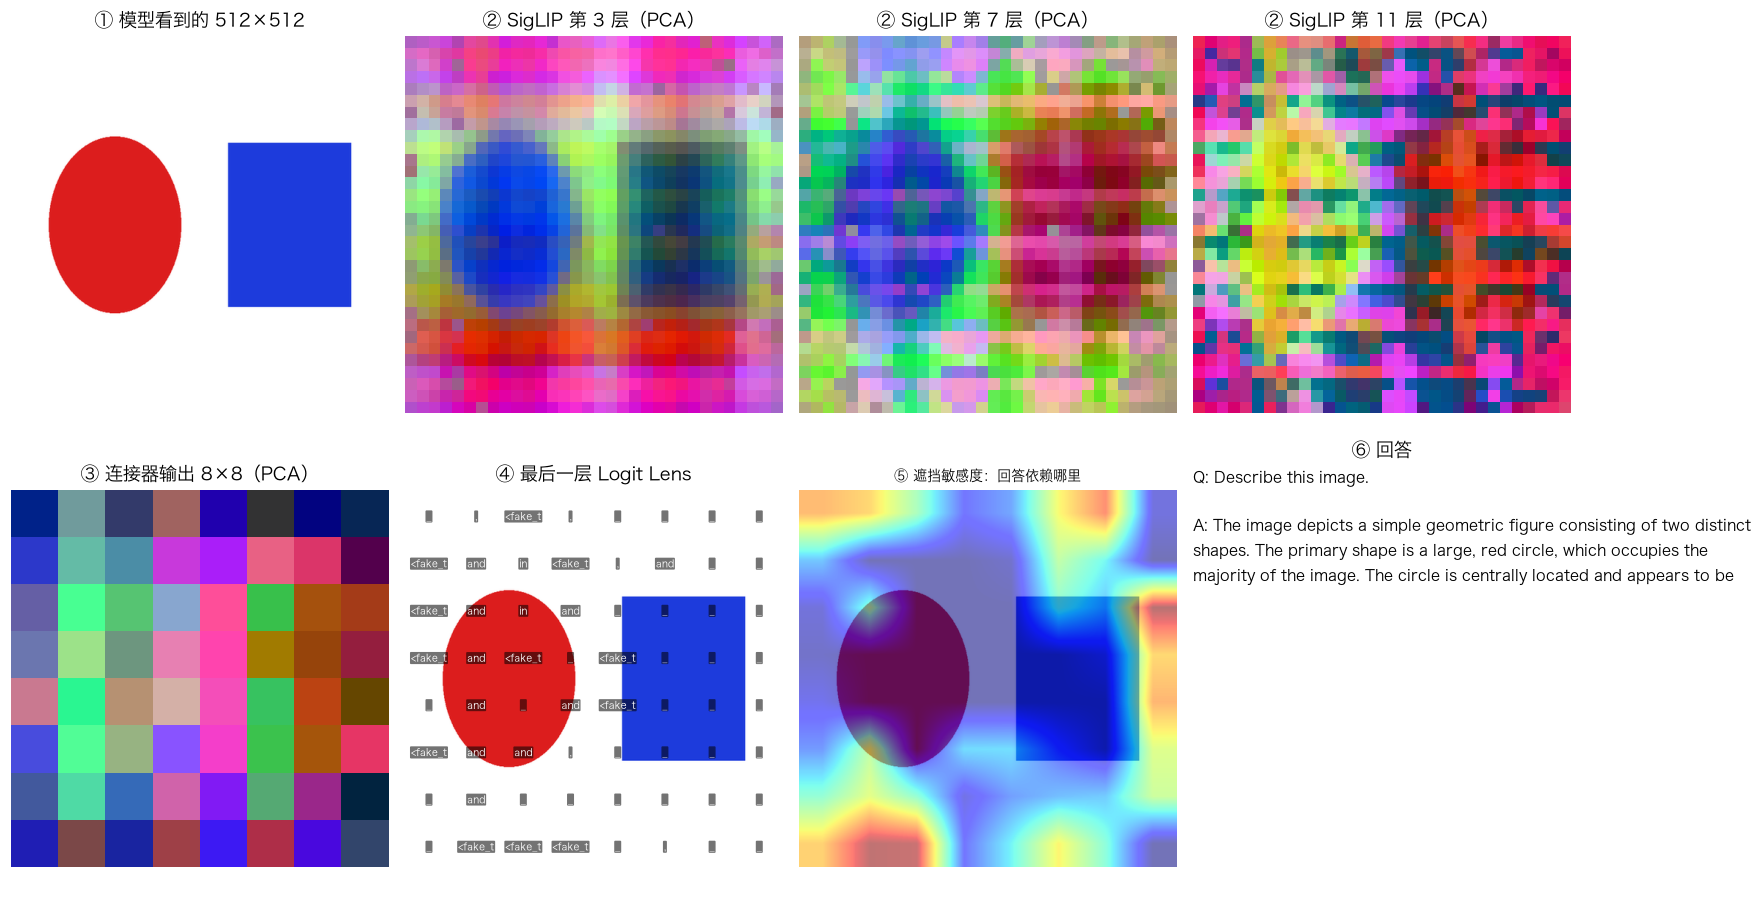

回答： The image depicts a simple geometric figure consisting of two distinct shapes. The primary shape is a large, red circle, which occupies the majority of the image. The circle is centrally located and appears to be


In [8]:
from PIL import Image, ImageDraw  # 画演示图
MY_PHOTO = None  # ← 改成 "/路径/你的照片.jpg"
MY_QUESTION = "Describe this image."  # ← 也可以换成别的问题
if MY_PHOTO is None:  # 没指定就画一张
    demo = Image.new("RGB", (800, 600), "white")  # 白底
    d = ImageDraw.Draw(demo)  # 画笔
    d.ellipse([80, 160, 360, 440], fill=(220, 30, 30))  # 左边红圆
    d.rectangle([460, 170, 720, 430], fill=(30, 60, 220))  # 右边蓝方
    MY_PHOTO = demo  # 用演示图
proc, m = loaded["500M"]  # 用大模型
res = explore(m, proc, MY_PHOTO, MY_QUESTION)  # 一键探索
print("回答：", res["answer"])  # 打印回答

> **读遮挡图时要小心**：在纯白背景上，把一格涂成灰色等于"凭空多画了一个灰色方块"，模型可能因此改口（比如多数出一个形状），所以背景格子反而显得"很重要"。遮挡法衡量的是"改动这里，回答变不变"，而改动本身也会引入新内容。这是遮挡法固有的局限。

## 6. 释放内存
两个模型共占约 3 GB 统一内存。不再需要时可以释放。

In [9]:
del loaded, m, proc  # 删除引用
import gc  # 垃圾回收
gc.collect()  # 回收 Python 对象
torch.mps.empty_cache() if torch.backends.mps.is_available() else None  # 释放 MPS 缓存（只在 Mac 上有）
print("已释放")  # 完成

已释放


## 全教程完结
| 章 | 你学到了什么 |
|---|---|
| 00 | PyTorch 张量、自动求导、`nn.Module`、hook |
| 01 | 卷积怎么提取边缘，CNN 如何逐层抽象 |
| 02 | 照片 → 512×512 小图 → `pixel_values`；`<image>` 占位符 |
| 03 | SigLIP：patch → 注意力 → 从颜色到语义；汇聚点与超大通道 |
| 04 | 连接器：pixel shuffle + 线性投影，1024 → 64 个 token |
| 05 | 语言模型如何读图像 token；Logit Lens |
| 06 | 逐词生成、KV Cache、遮挡实验 |
| 07 | 只训练连接器就能学会新任务 |
| 08 | LoRA、灾难性遗忘与特征保持 |
| 09 | 模型变大带来了什么，没带来什么；用自己的照片探索 |